In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as signal
import scipy.ndimage as nd
from PIL import Image

In [2]:
from google.colab import drive
drive.mount('/content/drive')
imgpath = '/content/drive/MyDrive/의료영상처리/과제'

Mounted at /content/drive


## 1. object counting에 사용할 image를 grayscale로 불러오기

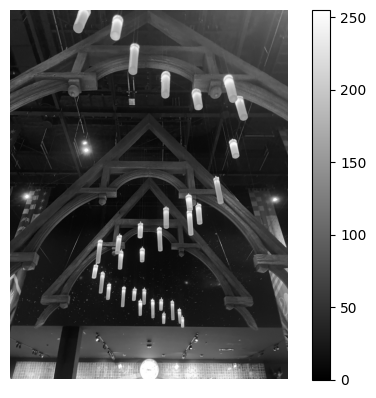

In [8]:
I = Image.open(imgpath+'/조명.jpeg').convert('L')
f = np.array(I)
plt.imshow(f,cmap='gray')
plt.axis('off')
plt.colorbar()
plt.show()

## 2. 적절한 전처리를 통해 영상의 noise를 줄이기

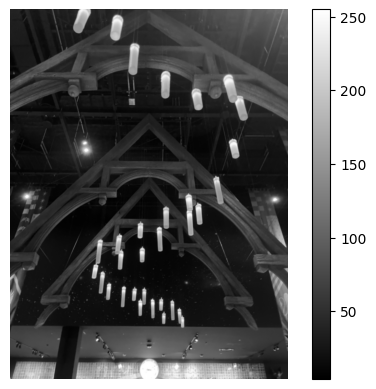

In [10]:
f_denoised = nd.gaussian_filter(f, sigma=3)
plt.imshow(f_denoised,cmap='gray')
plt.axis('off')
plt.colorbar()
plt.show()

## 3. 적절한 임계값을 찾아 thresholding을 통해 binary mask를 생성하기

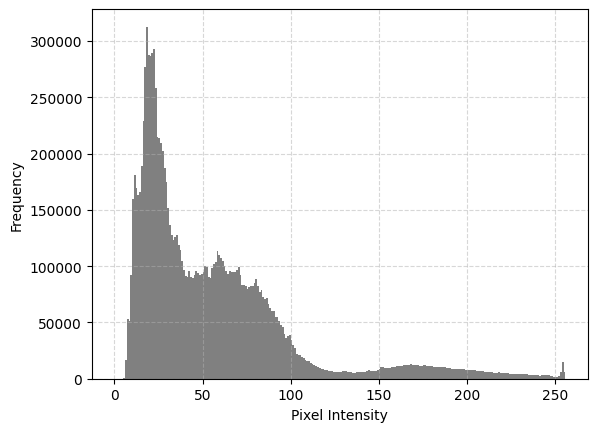

In [11]:
plt.hist(f_denoised.ravel(), bins=256, range=(0,256), color='gray')
plt.xlabel('Pixel Intensity')
plt.ylabel('Frequency')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

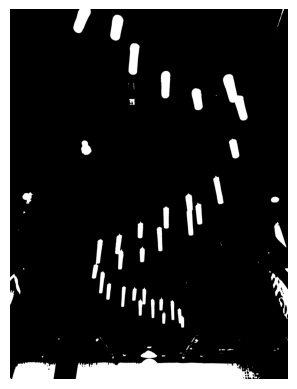

In [24]:
th_val = 128
f_mask = f_denoised > th_val
plt.imshow(f_mask,cmap='gray')
plt.axis('off')
plt.show()

=== 추출된 모든 객체(Components) 정보 ===


,Label_ID,Area (pixels),Width,Height
87,88,320605.0,1972,223
88,89,75039.0,475,185
7,8,54705.0,269,506
40,41,32321.0,185,499
5,6,31310.0,120,344
0,1,31085.0,190,263
2,3,29776.0,143,282
19,20,26836.0,87,461
6,7,26158.0,105,300
12,13,21596.0,121,240


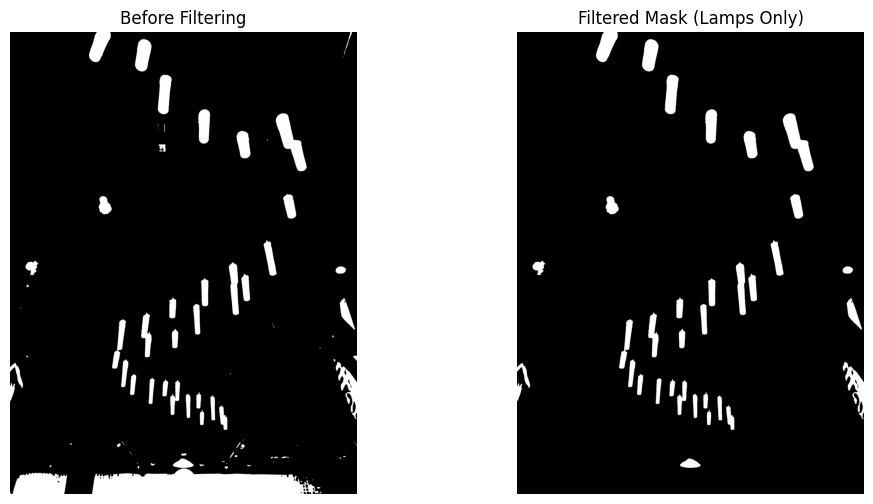

In [53]:
import pandas as pd
from skimage.measure import label, regionprops

initial_mask = f_denoised > 128

labeled_temp = label(initial_mask)
props = regionprops(labeled_temp)

print("=== 추출된 모든 객체(Components) 정보 ===")
info_list = []
for i, prop in enumerate(props):
    minr, minc, maxr, maxc = prop.bbox
    width = maxc - minc
    height = maxr - minr
    info_list.append({
        'Label_ID': prop.label,
        'Area (pixels)': prop.area,
        'Width': width,
        'Height': height
    })

info_df = pd.DataFrame(info_list)
# 보기 쉽게 면적(Area) 순으로 정렬하여 상위 20개 출력
display(info_df.sort_values(by='Area (pixels)', ascending=False).head(20))

min_allowed_area = 2700
min_allowed_width = 30
max_allowed_width = 350

filtered_mask = np.zeros_like(initial_mask)

for prop in props:
    minr, minc, maxr, maxc = prop.bbox
    width = maxc - minc

    if min_allowed_width <= width <= max_allowed_width and prop.area >= min_allowed_area:
        filtered_mask[labeled_temp == prop.label] = True

f_mask = filtered_mask

plt.figure(figsize=(12, 6))
plt.subplot(121)
plt.imshow(initial_mask, cmap='gray')
plt.title('Before Filtering')
plt.axis('off')

plt.subplot(122)
plt.imshow(f_mask, cmap='gray')
plt.title('Filtered Mask (Lamps Only)')
plt.axis('off')
plt.show()

## 4. Connected component 추출을 통해 object를 분리하고, 각각의 pixel수를 계산하기

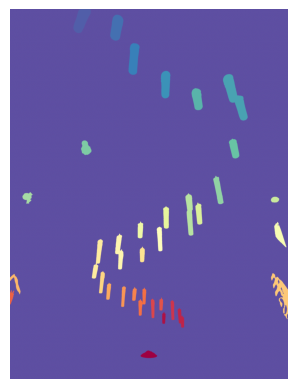

In [54]:
labels, nums = nd.label(f_mask)
plt.imshow(labels,cmap='Spectral_r')
plt.axis('off')
plt.show()

In [55]:
cc = np.zeros((nums-1,2))
for i in range(1,nums):
  cc[i-1,0] = i
  cc[i-1,1] = np.sum(labels==i)
  print(f'index: {int(cc[i-1,0])}, number of pixels: {int(cc[i-1,1])}')

index: 1, number of pixels: 31085
index: 2, number of pixels: 29776
index: 3, number of pixels: 31310
index: 4, number of pixels: 26158
index: 5, number of pixels: 54705
index: 6, number of pixels: 21596
index: 7, number of pixels: 16532
index: 8, number of pixels: 12515
index: 9, number of pixels: 18242
index: 10, number of pixels: 8259
index: 11, number of pixels: 26836
index: 12, number of pixels: 4516
index: 13, number of pixels: 13297
index: 14, number of pixels: 13250
index: 15, number of pixels: 9166
index: 16, number of pixels: 15076
index: 17, number of pixels: 12782
index: 18, number of pixels: 20597
index: 19, number of pixels: 20259
index: 20, number of pixels: 7706
index: 21, number of pixels: 9587
index: 22, number of pixels: 32321
index: 23, number of pixels: 7537
index: 24, number of pixels: 7084
index: 25, number of pixels: 7880
index: 26, number of pixels: 5439
index: 27, number of pixels: 12483
index: 28, number of pixels: 4105
index: 29, number of pixels: 4699
index

## 5. 추출한 connected component 중 가장 큰 것과 작은 것을 시각화하기

In [56]:
ind_max = np.argmax(cc[:,1])
print(f'the largest component: index {int(ind_max)}, # of pixels: {int(cc[ind_max,1])}')
ind_min = np.argmin(cc[:,1])
print(f'the smallest component: index {int(ind_min)}, # of pixels: {int(cc[ind_min,1])}')

the largest component: index 4, # of pixels: 54705
the smallest component: index 32, # of pixels: 3931


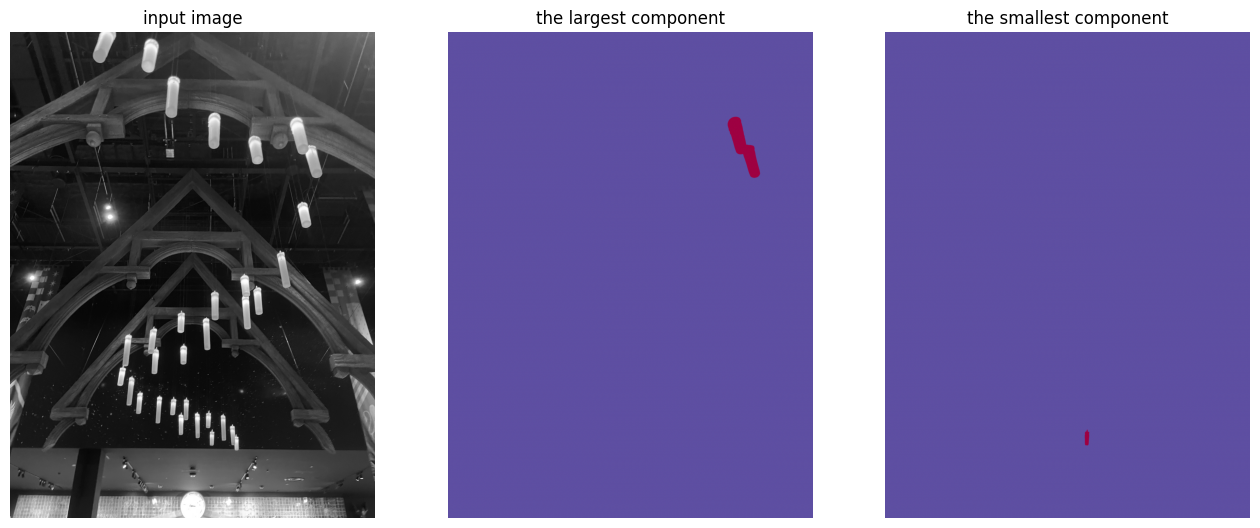

In [57]:
plt.figure(figsize=(16,9))
plt.subplot(131)
plt.imshow(f,cmap='gray')
plt.axis('off')
plt.title('input image')
plt.subplot(132)
plt.imshow(labels==cc[ind_max,0],cmap='Spectral_r')
plt.axis('off')
plt.title('the largest component')
plt.subplot(133)
plt.imshow(labels==cc[ind_min,0],cmap='Spectral_r')
plt.axis('off')
plt.title('the smallest component')
plt.show()